# a sanity check on an air layer to account for flight height

In [1]:
from em1d.experiment import Loop, Receiver
import matplotlib.pyplot as plt
import numpy as np
from numpy.linalg import norm

In [10]:
from em1d.transforms import precalcHankel1, Hankel, BaseFourier, CubicSpline
from em1d.physics import refl_transverse_electric as rte, freespace_u0 as u0, mu0
from em1d.experiment import getRz
import torch

def integrate_around_loop(lp, rx, hr):
    lp_xyz = lp.xyz - rx.xyz[None, ...]

    HR = 0+0j
    n_dipoles = 0
    for i in range(len(lp)-1):
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...i,...i->...', Rz, lp_xyz[i])
        p2 = torch.einsum('...i,...i->...', Rz, lp_xyz[i+1])

        p12 = p2-p1
        tdist = norm(p12, axis=-1)
        p12 /= tdist
        cp = p1
        cdist = 0

        while cdist < tdist:
            cR = norm(cp)
            ds = cR/15.
            if cdist+ds > tdist:
                ds = tdist-cdist
                cdist += cR/15
            else:
                cdist += ds
            HR += ds*p1[1]*hr(cR)/cR
            cp += ds*p12
            n_dipoles +=1
    return HR

class Forward:
    def __init__(self, source, receiver, times):
        self.source = source
        self.receiver = receiver
        self.times = torch.tensor(times)
        self.lgtimes = torch.log(self.times)

        self.rmin = self.source.min_horizontal_distance(self.receiver)
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.r = precalcHankel1.range(self.rmin, self.rmax)[0].numpy()
        print(self.r)
        # self.sofr = torch.tensor(self.source.s_of_r(self.receiver, self.r), dtype=torch.complex128)
        self.sofr = torch.tensor([0., 0., 2*np.pi*10], dtype=torch.complex128)
        self.dz = torch.tensor(self.receiver.z+self.source.z[0])

    def forward(self):
        def frq_integrand(omega):
            omega = omega[None,:,None]
            def integrand(wave_length):
                lmb = wave_length[None, None, :]
                tmp_u0 = u0(omega, lmb)
                
                intg = torch.squeeze((torch.exp(-tmp_u0*self.dz)*rte(self.sigma, self.thick, omega, lmb))*lmb**2 / tmp_u0)
                print('shape of hankel integrand: ', intg.shape)
                return intg
            
            hkl1 = Hankel(integrand, 1)
            r, hr = hkl1.range(self.rmin, self.rmax)
            hr /= r
            print('shape of hankel result (omega, r)', hr.shape)        
            # h1 = torch.squeeze(h1) / r[:,None]
            # cbhr = CubicSpline(r.real, h1)
            # res = cbhr(10.)
            # res = hr @ self.sofr
            # print('shape of fourier integrand', res.shape)
            return hr.T
        f_t=BaseFourier(frq_integrand, smp_per_decade=30)
        t,dbdt = f_t.range(self.times[0], self.times[-1])        
        print('shape of dbdt:', dbdt.shape)
        cbs = CubicSpline(t, dbdt[-1])
        return cbs(self.times)

    def __call__(self, sigma, thickness):
        self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
        self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]
        return self.forward()

In [11]:
ainv_dbdt=np.array([6.145711e-04, 3.319648e-04, 1.650304e-04, 8.868765e-05,
       4.967526e-05, 2.618016e-05, 1.444254e-05, 8.242962e-06,
       4.457639e-06, 2.520354e-06, 1.515021e-06, 8.744991e-07,
       4.584869e-07, 2.520399e-07, 1.447630e-07, 7.766509e-08,
       4.233407e-08, 2.387553e-08, 1.272288e-08, 6.846980e-09])

times = np.array([9.350e-06, 1.145e-05, 1.458e-05, 1.822e-05, 2.255e-05, 2.867e-05,
       3.595e-05, 4.460e-05, 5.660e-05, 7.070e-05, 8.630e-05, 1.071e-04,
       1.381e-04, 1.748e-04, 2.174e-04, 2.775e-04, 3.515e-04, 4.385e-04,
       5.575e-04, 7.035e-04])

In [12]:
# a = np.sqrt(40*40/np.pi)
a=10

In [17]:
lp = Loop.circle(a, n=100)
#lp = Loop.square(40, z=0.02)
rx = Receiver()#Receiver(z=0.02)

sigma = 1/torch.tensor([40,40,40,40,40])
thick = torch.tensor([1, 2, 20, 40])

# fwr = Forward(lp, rx, np.logspace(-9, -1, 51))
fwr = Forward(lp, rx, times)
from time import perf_counter as timer
bt = timer()
dbdt = fwr(sigma, thick)
print(dbdt.shape)

/home/matt/repositories/em1d/src/em1d/transforms/transforms.py:236: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  rout = torch.tensor(10**(i_offsets/self.smp_per_decade), dtype=torch.complex128)
/tmp/ipykernel_22934/1746081896.py:78: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     dtype=torch.complex128)[...,None,None]
/tmp/ipykernel_22934/1746081896.py:79: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]


[ 6.30957365+0.j  7.94328213+0.j 10.        +0.j]
shape of hankel integrand:  torch.Size([901, 301])
shape of hankel result (omega, r) torch.Size([901, 3])
shape of dbdt: torch.Size([3, 60])
torch.Size([20])


/home/matt/repositories/em1d/src/em1d/transforms/transforms.py:297: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  tout = torch.tensor(10**(i_offsets/self.smp_per_decade))


In [18]:
dhdt = (1./40)**(3/2) * mu0**(3/2) * a**2 * fwr.times.numpy()**(-5/2) / (20*np.sqrt(np.pi))

In [22]:
dhdt/dbdt.real

tensor([7.9346, 8.0587, 8.0129, 8.0467, 8.0942, 8.0524, 8.0479, 8.0547, 8.0333,
        8.0296, 8.0361, 8.0308, 8.0190, 8.0159, 8.0172, 8.0180, 8.0215, 8.0271,
        8.0340, 8.0430], dtype=torch.float64)

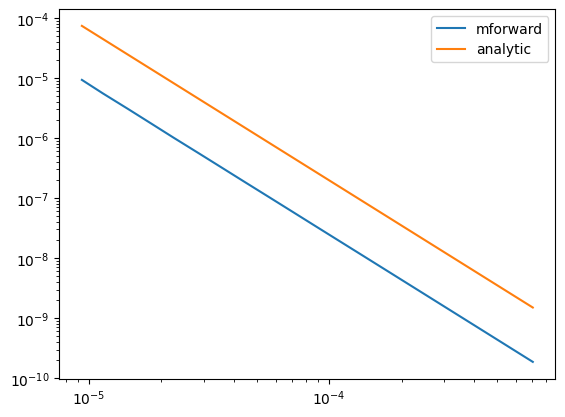

In [23]:
fig,ax = plt.subplots()
ax.loglog(fwr.times.numpy(), mu0*dbdt.real, label='mforward')
# ax.loglog(times,      ainv_dbdt, label='AarhusInv')
ax.loglog(fwr.times.numpy(),       dhdt*mu0, label='analytic')
ax.legend()